# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot PSL and wind vector composites by node over all times

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import dask

In [2]:
# set path where the som finalist files are
dir_base = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

## Load training data to interpret SOMs

In [3]:
# set input directory
dir_in = dir_base + 'som_training/'

In [4]:
def normalize_data(data):
    """
    Function for normalizing data prior to training using z-score
    """
    return (data - np.nanmean(data)) / np.nanstd(data)

In [5]:
# open file saved in earlier notebook (soms_antarctica-gettingdata.ipynb)
subset = xr.open_dataset(dir_in+'mesaclip_training_data_alaska_psl_autumn_decadal.nc')

# assign to numpy array object
subsetarray = subset['train_data'].values

# set data
data = normalize_data(subsetarray)

# set data input length
input_length = subsetarray.shape[1]    # using preprocessed data array; Number of the elements of the vectors in input.

## Set the parameter combinations for SOM finalists

In [6]:
# set paired values for possible winning maps based on Sammon maps evaluation
som_grid_rows    = [3, 4]    # (y-axis)
som_grid_cols    = [3, 4]    # (x-axis)
ranks            = [3, 45]
sigs             = [1.0, 1.0]
lrs              = [0.01, 0.005]
nitrs            = [250000, 50000]

## MANUAL CHANGING REQUIRED HERE ##
# select which set to plot
n = 0

In [7]:
# select info for input file (set above)
som_row = som_grid_rows[n]
som_col = som_grid_cols[n]
rank = ranks[n]
sig = sigs[n]
lr = lrs[n]
n_iter = nitrs[n]

In [8]:
# set the input name file from this
fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fin)

som_alaska_psl_3x3_sig1.0_lr0.01_iter250000


## Load pickles of "winning" combos and make assessment plots

In [9]:
# open pickle
with open(dir_in+'pickles/psl_som/'+fin+'.p', 'rb') as infile:
    som = pickle.load(infile)

In [10]:
# double check qerror
qerr = som.quantization_error(data)
print('quantization error: '+str(qerr))

quantization error: 26.348131518266264


In [11]:
# create an empty dictionary using the rows and columns of SOM
keys = [i for i in product(range(som_row),range(som_col))]
winmap = {key: [] for key in keys}

In [12]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# grab the indices for the data within the SOM lattice
for i, x in enumerate(data):
    winmap[som.winner(x)].append(i) 

# create list of the dictionary keys
som_keys = list(winmap.keys())
print(f"Number of composite maps: {len(som_keys)}")
print(f"The rows and columns of the SOM lattice to use to grab SOM indexes:\n{[i for i in list(winmap.keys())]}")

Number of composite maps: 9
The rows and columns of the SOM lattice to use to grab SOM indexes:
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


## Load data to make composites
- not identical to training data so we can see larger area patterns
- Need PSL, UBOT, VBOT

In [13]:
# set input directory
dir_in = dir_base + 'data_for_composites/'

ds_psl = xr.open_dataset(dir_in + 'PSL_autumn_decadal_alaska_cam_grid.nc')   # lazy, nothing loaded
nens, ndec, ndays = (ds_psl.sizes[d] for d in ('ensemble', 'decades', 'autumn_days'))
lat, lon = ds_psl.lat, ds_psl.lon
nodes = list(range(len(som_keys)))

# the SOM indices refer to the stacked (ensemble, decades, autumn_days) order,
# so label each time with its node and reshape back to that order
assert subsetarray.shape[0] == nens * ndec * ndays, 'training data length does not match composite files'

node_of_time = np.full(nens * ndec * ndays, -1, dtype=int)
for map_num, key in enumerate(som_keys):
    node_of_time[winmap[key]] = map_num
assert (node_of_time >= 0).all(), 'some times were not assigned to a node'
node_of_time = node_of_time.reshape(nens, ndec, ndays)

In [14]:
def make_composite(var_in, anomaly=False):
    """Mean of var_in for each SOM node, never holding more than one ensemble member in memory.
    anomaly=True: convert Pa -> hPa and subtract the daily spatial mean (as in your original PSL code)."""
    ds = xr.open_dataset(f'{dir_in}{var_in}_autumn_decadal_alaska_cam_grid.nc')
    nlat, nlon = ds.sizes['lat'], ds.sizes['lon']
    sums = np.zeros((len(nodes), nlat, nlon))
    cnts = np.zeros((len(nodes), nlat, nlon))

    for e in range(nens):
        da = (ds[var_in].isel(ensemble=e)
                .transpose('decades', 'autumn_days', 'lat', 'lon')
                .load())
        if anomaly:
            da = da / 100.0
            da = da - da.mean(dim=['lat', 'lon'])
        vals = da.values.reshape(-1, nlat, nlon)
        labels = node_of_time[e].reshape(-1)

        for node in nodes:
            sel = vals[labels == node]
            if sel.shape[0] == 0:
                continue
            sums[node] += np.nansum(sel, axis=0)
            cnts[node] += np.isfinite(sel).sum(axis=0)
        print(f'{var_in}: ensemble member {e + 1}/{nens} done')

    ds.close()
    comp = sums / np.where(cnts > 0, cnts, np.nan)    # nan-aware mean, like skipna=True
    return xr.DataArray(comp, dims=('node', 'lat', 'lon'),
                        coords={'node': nodes, 'lat': lat, 'lon': lon})

In [15]:
psl_composite_all  = make_composite('PSL', anomaly=True)
ubot_composite_all = make_composite('UBOT')
vbot_composite_all = make_composite('VBOT')
print(psl_composite_all.shape)

PSL: ensemble member 1/9 done
PSL: ensemble member 2/9 done
PSL: ensemble member 3/9 done
PSL: ensemble member 4/9 done
PSL: ensemble member 5/9 done
PSL: ensemble member 6/9 done
PSL: ensemble member 7/9 done
PSL: ensemble member 8/9 done
PSL: ensemble member 9/9 done
UBOT: ensemble member 1/9 done
UBOT: ensemble member 2/9 done
UBOT: ensemble member 3/9 done
UBOT: ensemble member 4/9 done
UBOT: ensemble member 5/9 done
UBOT: ensemble member 6/9 done
UBOT: ensemble member 7/9 done
UBOT: ensemble member 8/9 done
UBOT: ensemble member 9/9 done
VBOT: ensemble member 1/9 done
VBOT: ensemble member 2/9 done
VBOT: ensemble member 3/9 done
VBOT: ensemble member 4/9 done
VBOT: ensemble member 5/9 done
VBOT: ensemble member 6/9 done
VBOT: ensemble member 7/9 done
VBOT: ensemble member 8/9 done
VBOT: ensemble member 9/9 done
(9, 160, 240)


## Plot composite maps of psl anomaly across lattice

In [16]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'
fout = 'figure_2_som_alaska_'+str(som_row)+'x'+str(som_col)+'_PSLanom_wind_vectors_composite.png'
print(fout)

figure_2_som_alaska_3x3_PSLanom_wind_vectors_composite.png


In [17]:
## set colors
cmap_choice = plt.cm.get_cmap('coolwarm')

# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 218
lon_min = 182
lon_avg = 200

# set plotting info
title = 'PSL'
units = 'hPa'
vmin_in = -28.0
vmax_in = 28.0 
levels_in = np.arange(vmin_in,vmax_in+2,2)
ticks_1 = levels_in
intv = 5

In [18]:
# set node names
node_names = ['0a', '0b', '0c', '1a', '1b', '1c', '2a', '2b', '2c']

In [20]:
# set paired lists with name and lat/lon
# main villages
village_names_1 = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats_1 =  [66.257, 64.501, 63.879, 63.694,63.77611]
village_lons_1 =  [-166.072, -165.406, -160.790, -170.479,-171.70083]

# other villages names - 
# Utqiagvik, Wrainwright, Point Lay, Point Hope, Kivalina, Kotzebue, Deering, Wales, Teller, Brevig Mission, 
# Solomon, Golovin, Elim, Koyuk, Shaktoolik, St. Michaels, Stebbins, Kotlik, Emmonak, Alakanuk
# Nunam Iqua, Scammon Bay, Paimiut, Hooper Bay, Chevak, Newtok, Tununak, Umkumiut, Nunakauyarmiut
# Nightmute, Chefornak, Kipnuk, Kwigillingok, Kongiganak, Tuntutuliak, Eek, Kwinhagak, Platinum, Goodnews Bay, Togiak,
# Aleut Community of St. Paul, Aleut Community of St. George, Mekoryuk, Gambell, King Island, Little Diomede Island
village_lats_2 =  [71.29,70.638,69.7438,68.347052,67.7272,66.898331,66.07583,65.61222,65.26349,65.3347,\
                   64.55876,64.54333,64.6178,64.9311,64.3556,63.478526,63.51194,63.0358,62.7722,62.68889,\
                   62.516094,61.8425,61.70083,61.531111,61.52778,60.9428,60.5805,60.4996528,60.53381,\
                   60.49139,60.15907,59.9390,59.872266,59.953896,60.3426,60.218662,59.753374,59.008483,59.121408,59.06194,\
                   57.1250,56.60556,60.389278,63.77611,64.9750,65.754]
village_lons_2 =  [-156.79,-160.033,-163.0084,-166.762917,-164.5392,-162.596664,-162.71833,-168.08917,-166.36244,-166.4892,\
                   -164.44327,-163.02917,-162.2567,-161.1586,-161.1913,-162.037123,-162.27472,-163.5603,-164.5450,-164.61528,\
                   -164.895198,-165.5817,-165.83861,-166.096667,-165.57861,-164.6311,-165.2595,-165.1988583,-165.10374,\
                   -164.82611,-164.269437,-164.0370,-163.166165,-162.895199,-162.6727,-162.025928,-161.902701,-161.814750,-161.585835,-160.37639,\
                   -170.2708,-169.55972,-166.207082,-171.70083,-168.0597,-168.921]

nvillages_1 = len(village_names_1)
nvillages_2 = len(village_lats_2)

In [24]:
## box 1, Bering Sea
box1_latmin = 62
box1_latmax = 68
box1_lonmin = -173.
box1_lonmax = -160.

lon_pts = [box1_lonmin,box1_lonmax,box1_lonmax,box1_lonmin,box1_lonmin]
lat_pts = [box1_latmax,box1_latmax,box1_latmin,box1_latmin,box1_latmax]

### Plot anomalies over all time

node: 0
node: 1
node: 2
node: 3
node: 4
node: 5
node: 6
node: 7
node: 8


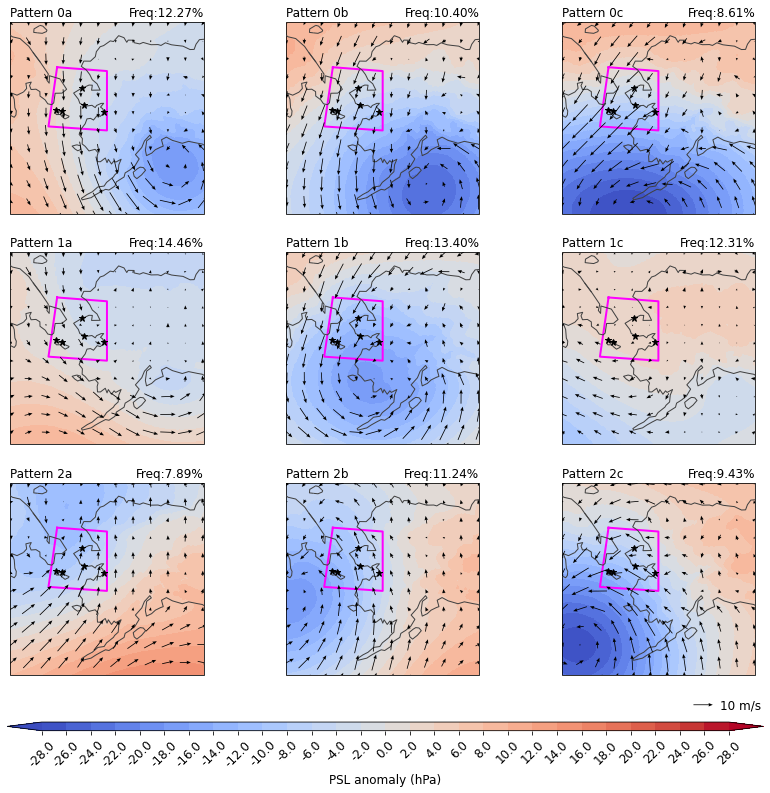

In [29]:
# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, subplot_kw={'projection':ccrs.Stereographic(central_longitude=lon_avg)}, figsize=(14,12))

# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
    print('node: '+str(map_num))
    # grab the composite data that corresponds to those training times and node
    psl_sub = psl_composite_all.isel(node=map_num)
    ubot_sub = ubot_composite_all.isel(node=map_num)
    vbot_sub = vbot_composite_all.isel(node=map_num)

    # make plot for this node - note using .values converts from xarray to numpy array
    cs = axs[som_keys[map_num][0],som_keys[map_num][1]].contourf(lon, lat, psl_sub.values,
                                                                 levels=levels_in, extend='both', cmap=cmap_choice, transform=ccrs.PlateCarree())
    # add vectors
    #vc = axs[som_keys[map_num][0],som_keys[map_num][1]].quiver(lon, lat, ubot_sub.values, vbot_sub.values,
    #                                                           regrid_shape=20, color='black',linewidth=1.0, transform=ccrs.PlateCarree())
    # add vectors
    ax_now = axs[som_keys[map_num][0], som_keys[map_num][1]]
    vc = ax_now.quiver(lon, lat, ubot_sub.values, vbot_sub.values,
                       regrid_shape=20, color='black', scale=100,
                       width=0.004,          # shaft thickness
                       headwidth=4.5,        # head width, in multiples of the shaft width
                       headlength=5.5,       # head length
                       headaxislength=5,     # how far the head notch cuts in
                       pivot='middle', zorder=21,
                       transform=ccrs.PlateCarree())

    # add primary village locations and names
    axs[som_keys[map_num][0],som_keys[map_num][1]].plot(village_lons_1, village_lats_1, marker="*", markersize=7, linestyle='none', color='black',zorder=100,transform=ccrs.PlateCarree())

    # add box for Bering St
    axs[som_keys[map_num][0],som_keys[map_num][1]].plot(lon_pts, lat_pts, color='magenta', linewidth=2,transform=ccrs.PlateCarree())
    
    # modify the plots
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_extent([lon_min,lon_max,lat_min,lat_max])
    axs[som_keys[map_num][0],som_keys[map_num][1]].coastlines(resolution='110m', color='0.25', linewidth=1.0, zorder=10)
    
    # plot titles
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Pattern '+node_names[map_num], loc="left",fontsize=12)
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Freq:{:.2f}'.format(frequencies.flatten()[map_num])+'%', loc="right",fontsize=12)

# finalize figure 
#plt.suptitle('Alaska SOM node composite '+title+' anomaly - '+times, fontsize=12, x=0.515, y=0.925)

# colorbar stuff
cbar_ax = fig.add_axes([0.14, 0.06, 0.75, 0.01]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_1[:], orientation='horizontal')
cbar.ax.set_xticklabels(list(ticks_1))
cbar.ax.tick_params(labelsize=12,rotation=45)
cbar.set_label('PSL anomaly ('+units+')', fontsize=12)
# quiver key - one shared vector key for all panels, placed in figure coordinates at the bottom right
axs[-1, -1].quiverkey(vc, X=0.84, Y=0.09, U=10, label='10 m/s', labelpos='E',
                      coordinates='figure', fontproperties={'size': 12})

# save figure
plt.savefig(fout, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+fout, bbox_inches='tight', dpi=200)